## Introducción al Proyecto: Recomendación de Planes Megaline

**Contexto del Problema**

La compañia móvil Megaline enfrenta un desafío importante: muchos de sus clientes siguen utilizando planes heredados en lugar de migrar a sus nuevos planes Smart y Ultra. Para abordar esta situación, la empresa busca desarrollar un sistema inteligente que pueda analizar el comportamiento de uso de sus clientes y recomendar automáticamente el plan más adecuado.

**Objetivo del Proyecto**

Desarrollar un modelo de **clasificación binaria** que pueda predecir qué plan (Smart o Ultra) es más conveniente para cada cliente basándose en sus patrones de uso mensual. El modelo debe alcanzar una exactitud mínima de 0.75 para ser considerado viable para implementación.

**Datos Disponibles**

Trabajaremos en un dataset que contiene información del comportamieneto mensual de usuarios que ya migraron a los nuevos planes. Las variables incluyen:

+ **calls:** Número de llamadas realizadas.
+ **minutes:** Duración total de llamadas en minutos.
+ **messages:** Número de mensajes de texto enviados.
+ **mb_used:** Tráfico de internet utilizado en MB.
+ **is_ultra:** Variable objetivo (1 = Plan Ultra, 0 = Plan Smart)

**Metodología**
1. Exploración y análisis de los datos de comportamiento.
2. Segmentación en conjuntos de entrenamiento, validación y prueba.
3. Entrenamiento y evaluación de diferentes modelos de machine learning
4. Optimización de hiperparámetros para maximizar la exactitud.
5. Validación final con datos de prueba no vistos durante el entrenamiento.

### 1. Exploración y análisis de los datos

##### 1.1.Carga del Data Set

In [1]:
#cargar liberías
import pandas as pd
import numpy as np
from scipy import stats as st
import seaborn as sns
from matplotlib import pyplot as plt
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [2]:
#cargar los datos
df = pd.read_csv('/datasets/users_behavior.csv', sep=',', encoding='utf-8', quotechar= '"')

#información general
print("Información general del Data Frame:")
print(df.info())

Información general del Data Frame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3214 entries, 0 to 3213
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   calls     3214 non-null   float64
 1   minutes   3214 non-null   float64
 2   messages  3214 non-null   float64
 3   mb_used   3214 non-null   float64
 4   is_ultra  3214 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 125.7 KB
None


##### 1.2.Información general (shape, tipos de datos, valores faltantes)

In [3]:
print(f"Forma del DataFrame: {df.shape}")
print(f"Valores faltantes por columna:")
print(df.isnull().sum())
print()
print("Vista del DataFrame:")
display(df)

Forma del DataFrame: (3214, 5)
Valores faltantes por columna:
calls       0
minutes     0
messages    0
mb_used     0
is_ultra    0
dtype: int64

Vista del DataFrame:


,calls,minutes,messages,mb_used,is_ultra
0,40.0,311.90,83.0,19915.42,0
1,85.0,516.75,56.0,22696.96,0
2,77.0,467.66,86.0,21060.45,0
3,106.0,745.53,81.0,8437.39,1
4,66.0,418.74,1.0,14502.75,0
...,...,...,...,...,...
3209,122.0,910.98,20.0,35124.90,1
3210,25.0,190.36,0.0,3275.61,0
3211,97.0,634.44,70.0,13974.06,0
3212,64.0,462.32,90.0,31239.78,0


### Observaciones Iniciales
#### Estructura del Dataset
- **Tamaño**: 3,214 usuarios con 5 columnas
- **Calidad**: Sin valores faltantes en ninguna variable
- **Estado**: Datos ya procesados del análisis estadístico previo
#### Variables del Dataset
- **Características de uso**: 'calls', 'minutes', 'messages', 'mb_used' (valores decimales)
- **Variable Objetivo**: 'is_ultra' (0 = Plan Smart, 1 = Plan Ultra)
#### Observación preliminar
- En la muestra visible, la mayoría de los usuarios tienen plan Smart
- Los datos mantienen precisión decimal, lo cual es beneficioso para los algoritmos de ML.

##### 1.3. Análisis estadístico descriptivo

In [4]:
#Estadísticas básicas
print(df.describe())

             calls      minutes     messages       mb_used     is_ultra
count  3214.000000  3214.000000  3214.000000   3214.000000  3214.000000
mean     63.038892   438.208787    38.281269  17207.673836     0.306472
std      33.236368   234.569872    36.148326   7570.968246     0.461100
min       0.000000     0.000000     0.000000      0.000000     0.000000
25%      40.000000   274.575000     9.000000  12491.902500     0.000000
50%      62.000000   430.600000    30.000000  16943.235000     0.000000
75%      82.000000   571.927500    57.000000  21424.700000     1.000000
max     244.000000  1632.060000   224.000000  49745.730000     1.000000


#### Observaciones del análisis descriptivo:

**Información general del dataset:**
- **Tamaño:** 3,214 usuarios con 5 variables
- **Datos faltantes:** Ninguno (todas las variables tienen 3,214 valores no nulos)
- **Tipos de datos:** 4 variables numéricas (float64) y 1 categórica (int64)

**Estadísticas por variable:**

**CALLS (llamadas):**
- Promedio: 63.04 llamadas por usuario
- Mediana: 62 llamadas (distribución relativamente simétrica)
- Rango: 0 - 244 llamadas
- 75% de usuarios hace 82 llamadas o menos

**MINUTES (minutos):**
- Promedio: 438.21 minutos por usuario
- Mediana: 430.60 minutos (distribución relativamente simétrica)
- Rango: 0 - 1,632.06 minutos
- Desviación estándar: 234.57 (variación moderada)

**MESSAGES (mensajes):**
- Promedio: 38.28 mensajes por usuario
- Mediana: 30 mensajes (distribución ligeramente sesgada)
- Rango: 0 - 224 mensajes
- 25% de usuarios envía 9 mensajes o menos

**MB_USED (datos móviles):**
- Promedio: 17,207.67 MB por usuario
- Mediana: 16,943.24 MB
- **Observación importante:** Alta variabilidad (desviación estándar: 7,570.97)
- Rango: 0 - 49,745.18 MB
- Usuarios con consumo extremo: algunos consumen más del doble que el 75% de la población

**IS_ULTRA (tipo de plan):**
- Promedio: 0.31 (31% de usuarios tienen plan Ultra)
- 69% de usuarios tienen plan Smart

##### 1.4. Distribución de la variable objetivo

En esta sección analizaremos la distribución de la variable objetivo 'is_ultra', que indica el tipo de plan del usuario:
- **0**: Plan Smart
- **1**: Plan Ultra

**¿Por qué es importante este análisis?**
- Nos permite identificar si el dataset está balanceado o desbalanceado
- Un desbalance significativo puede afectar el rendimiento del modelo de machine learning
- Nos ayuda a entender la proporción real de usuarios en cada plan
- Determina si necesitaremos técnicas especiales para manejar clases desbalanceadas

**Métricas a analizar:**
- Conteo absoluto de usuarios por tipo de plan
- Distribución porcentual
- Estadísticas descriptivas básicas

In [5]:
# 1.4 Distribución de la variable objetivo
print("=== DISTRIBUCIÓN DE LA VARIABLE OBJETIVO (is_ultra) ===")
print()

# Conteo de valores
print("Conteo de usuarios por tipo de plan:")
print(df['is_ultra'].value_counts().sort_index())
print()

# Porcentajes
print("Distribución porcentual:")
print(df['is_ultra'].value_counts(normalize=True).sort_index() * 100)
print()

# Estadísticas básicas de la variable objetivo
print("Estadísticas básicas de is_ultra:")
print(df['is_ultra'].describe())

=== DISTRIBUCIÓN DE LA VARIABLE OBJETIVO (is_ultra) ===

Conteo de usuarios por tipo de plan:
0    2229
1     985
Name: is_ultra, dtype: int64

Distribución porcentual:
0    69.352831
1    30.647169
Name: is_ultra, dtype: float64

Estadísticas básicas de is_ultra:
count    3214.000000
mean        0.306472
std         0.461100
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max         1.000000
Name: is_ultra, dtype: float64


#### Observaciones del análisis de la variable objetivo:

**Distribución encontrada:**
- **Plan Smart (0):** 2,229 usuarios (69.35%).
- **Plan Ultra (1):** 985 usuarios (30.65%).

**Interpretación:**
- **Dataset moderadamente desbalanceado:** Proporción aproximada 70-30.
- **Suficientes ejemplos:** 985 usuarios Ultra es una cantidad adecuada para entrenar el modelo.
- **Distribución realista:** Es lógico que más usuarios tengan el plan básico que el premium.

**Implicaciones para el modelo:**
- El desbalance no es extremo, pero debemos monitorearlo.
- Un modelo que siempre prediga "Plan Smart" tendría 69.35% de precisión.
- Nuestro modelo debe superar significativamente este baseline.
- Podríamos considerar técnicas de balanceo si el rendimiento es bajo.

In [6]:
#Comparación de la distribución de cada variable numérica entre ambos planes
df.groupby('is_ultra').describe()

calls                                                      minutes  \
           count       mean        std  min   25%   50%    75%    max   count   
is_ultra                                                                        
0         2229.0  58.463437  25.939858  0.0  40.0  60.0   76.0  198.0  2229.0   
1          985.0  73.392893  43.916853  0.0  41.0  74.0  104.0  244.0   985.0   

                      ... messages        mb_used                              \
                mean  ...      75%    max   count          mean           std   
is_ultra              ...                                                       
0         405.942952  ...     51.0  143.0  2229.0  16208.466949   5870.498853   
1         511.224569  ...     79.0  224.0   985.0  19468.823228  10087.178654   

                                                       
          min       25%       50%       75%       max  
is_ultra                                               
0         0.0  12643.05  16506.93  20043.06  38552.62  
1         0.0  11770.28  19308.01  26837.72  49745.73  

[2 rows x 32 columns]

In [7]:
#Crear una tabla dinámica con las estadísticas descriptivas
pivot_stats = df.groupby('is_ultra').describe().round(2)
print("Tabla dinámica de estadísticas descriptivas por plan:")
print(pivot_stats)

Tabla dinámica de estadísticas descriptivas por plan:
           calls                                              minutes          \
           count   mean    std  min   25%   50%    75%    max   count    mean   
is_ultra                                                                        
0         2229.0  58.46  25.94  0.0  40.0  60.0   76.0  198.0  2229.0  405.94   
1          985.0  73.39  43.92  0.0  41.0  74.0  104.0  244.0   985.0  511.22   

          ... messages        mb_used                                     \
          ...      75%    max   count      mean       std  min       25%   
is_ultra  ...                                                              
0         ...     51.0  143.0  2229.0  16208.47   5870.50  0.0  12643.05   
1         ...     79.0  224.0   985.0  19468.82  10087.18  0.0  11770.28   

                                        
               50%       75%       max  
is_ultra                                
0         16506.93  20043.06  38552.

In [8]:
# Crear una tabla más específica con métricas clave
summary_table = df.groupby('is_ultra').agg({
    'calls': ['mean', 'median', 'std'],
    'minutes': ['mean', 'median', 'std'],
    'messages': ['mean', 'median', 'std'],
    'mb_used': ['mean', 'median', 'std']
}).round(2)

print("Resumen comparativo por plan:")
display(summary_table)

Resumen comparativo por plan:


calls               minutes                 messages                \
           mean median    std    mean  median     std     mean median    std   
is_ultra                                                                       
0         58.46   60.0  25.94  405.94  410.56  184.51    33.38   28.0  28.23   
1         73.39   74.0  43.92  511.22  502.55  308.03    49.36   38.0  47.80   

           mb_used                      
              mean    median       std  
is_ultra                                
0         16208.47  16506.93   5870.50  
1         19468.82  19308.01  10087.18

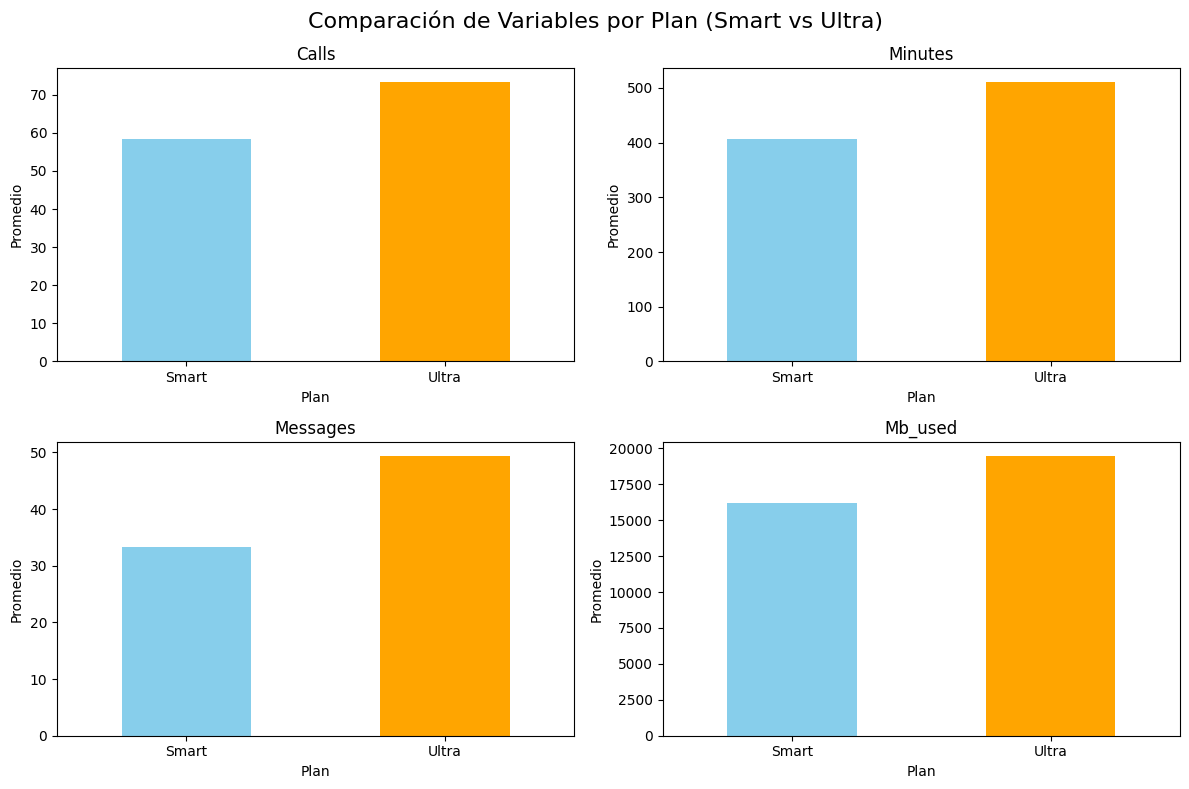

In [9]:
# Crear subplots para las 4 variables
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Comparación de Variables por Plan (Smart vs Ultra)', fontsize=16)

# Obtener los datos agrupados
means_data = df.groupby('is_ultra')[['calls', 'minutes', 'messages', 'mb_used']].mean()

# Variables y sus posiciones en la cuadrícula
variables = ['calls', 'minutes', 'messages', 'mb_used']
positions = [(0,0), (0,1), (1,0), (1,1)]

# Crear cada gráfico
for var, pos in zip(variables, positions):
    means_data[var].plot(kind='bar', ax=axes[pos], color=['skyblue', 'orange'])
    axes[pos].set_title(f'{var.capitalize()}')
    axes[pos].set_xlabel('Plan')
    axes[pos].set_ylabel('Promedio')
    axes[pos].set_xticklabels(['Smart', 'Ultra'], rotation=0)

plt.tight_layout()
plt.show()

#### Interpretación de Gráficos Comparativos

###### Distribución y Patrones Observados

Los gráficos revelan diferencias consistentes en el comportamiento de uso entre los planes Smart y Ultra:

- **Llamadas**: Los usuarios Ultra realizan aproximadamente 24% más llamadas que los usuarios Smart.
- **Minutos**: Los usuarios Ultra hablan 25% más minutos que los usuarios Smart.  
- **Mensajes**: Los usuarios Ultra envían 47% más mensajes que los usuarios Smart.
- **Datos**: Los usuarios Ultra consumen 25% más MB que los usuarios Smart.

Los usuarios Ultra representan más de la mitad de la base de usuarios comparado con Smart.

###### Hallazgos del Análisis Estadístico Anterior

Del sprint de estadística se identificó que los usuarios Smart frecuentemente exceden sus límites y terminan pagando más que el costo del plan Ultra.

###### Implicaciones para el Modelo de Machine Learning

Estas diferencias consistentes en todas las variables proporcionan señales claras para que el modelo pueda distinguir entre tipos de usuarios. El objetivo es identificar usuarios Smart que por su patrón de consumo serían mejores candidatos para el plan Ultra, especialmente aquellos que exceden límites y pagan sobrecargos innecesarios.

### 2. Segmentación de datos

#### Estrategia de Segmentación
Los datos se dividirán en tres conjuntos independientes para garantizar una evaluación robusta del modelo:

- **Entrenamiento (60%):** Conjunto principal para entrenar los modelos.
- **Validación (20%):** Conjunto para ajustar hiperparámetros y seleccionar el mejor modelo.
- **Prueba (20%):** Conjunto final para evaluar el rendimiento real del modelo.

##### 2.1. División en conjuntos de entrenamiento, validación y prueba

In [10]:
# Definir características (features) y variable objetivo (target)
features = df.drop('is_ultra', axis=1)  # Todas las columnas excepto is_ultra
target = df['is_ultra']  # Solo la columna is_ultra

# Primera división: 60% entrenamiento, 40% temporal
features_train, features_temp, target_train, target_temp = train_test_split(features, target, test_size=0.4, random_state=12345)

# Segunda división: del 40% temporal, hacer 20% validación y 20% prueba
features_valid, features_test, target_valid, target_test = train_test_split(features_temp, target_temp, test_size=0.5, random_state=12345)

# Verificar los tamaños de los conjuntos
print("Tamaños de los conjuntos:")
print(f"Conjunto original: {len(df)} muestras")
print(f"Entrenamiento: {len(features_train)} muestras ({len(features_train)/len(df)*100:.1f}%)")
print(f"Validación: {len(features_valid)} muestras ({len(features_valid)/len(df)*100:.1f}%)")
print(f"Prueba: {len(features_test)} muestras ({len(features_test)/len(df)*100:.1f}%)")

# Verificar que las formas coincidan
print("\nFormas de los conjuntos:")
print(f"features_train: {features_train.shape}, target_train: {target_train.shape}")
print(f"features_valid: {features_valid.shape}, target_valid: {target_valid.shape}")
print(f"features_test: {features_test.shape}, target_test: {target_test.shape}")

Tamaños de los conjuntos:
Conjunto original: 3214 muestras
Entrenamiento: 1928 muestras (60.0%)
Validación: 643 muestras (20.0%)
Prueba: 643 muestras (20.0%)

Formas de los conjuntos:
features_train: (1928, 4), target_train: (1928,)
features_valid: (643, 4), target_valid: (643,)
features_test: (643, 4), target_test: (643,)


#### 2.2. Justificación del tamaño de cada conjunto

####  Proporción 60-20-20

Esta distribución es ampliamente utilizada en machine learning porque:

1. **Suficientes datos de entrenamiento:** El 60% proporciona una base sólida para que los algoritmos aprendan patrones.
2. **Validación efectiva:** El 20% permite una evaluación confiable durante el desarrollo.
3. **Prueba representativa:** El 20% final ofrece una estimación realista del rendimiento en datos no vistos.
4. **Equilibrio:** Evita el sobreajuste mientras mantiene suficientes datos para cada propósito.

#### Parámetros Técnicos
- **random_state=12345**: Garantiza reproducibilidad de los resultados
- **División estratificada**: Mantiene la proporción de clases en cada conjunto

### 3. Entrenamiento y evaluación de modelos

En esta sección exploraremos diferentes algoritmos de machine learning para resolver nuestro problema de clasificación binaria: predecir si un cliente debe usar el Plan Smart (0) o Ultra (1) basándonos en su comportamiento de uso.

El objetivo será encontrar el modelo con la mayor exactitud posible, superando el umbral mínimo de 0.75.

**Metodología**:
- Entrenaremos cada modelo con el conjunto de entrenamiento (60%).
- Optimizaremos hiperparámetros usando el conjunto de validación (20%)
- Seleccionaremos el mejor modelo basado en el rendimiento de validación.


##### 3.1. Prueba de diferentes algoritmos

Los algoritmos que investigaremos son DecisionTree, RandomForest y LogisticRegressio, cada uno con diferentes fortalezas para este tipo de problema.  En este primer paso, usaremos los parámetros por defecto para entender el comportamiento básico de cada algoritmo.

#### 3.1.1. DecisionTree

**¿Qué es?** Un algoritmo que crea un árbol de decisiones basado en las características de los datos, dividiento el dataset en ramas hasta llegar a una predicción.

Es útil para nuestro problema porque maneja bien datos categóricos y numéricos. También es interpretable porque podemos ver qué decisiones toma y no requiere normalizacion de los datos.

In [11]:
# Modelo Decision Tree con parámetros por defecto
print("=== DECISION TREE (Parámetros por defecto) ===")

# Crear el modelo con parámetros por defecto
model_dt = DecisionTreeClassifier(random_state=12345)

# Entrenar el modelo
model_dt.fit(features_train, target_train)

# Hacer predicciones en el conjunto de validación
predictions_dt = model_dt.predict(features_valid)

# Calcular la exactitud
accuracy_dt = accuracy_score(target_valid, predictions_dt)

print(f"Exactitud en validación: {accuracy_dt:.4f}")

=== DECISION TREE (Parámetros por defecto) ===
Exactitud en validación: 0.7138


##### Observaciones del Decision Tree (parámetros por defecto)

El modelo Decision Tree con parámetros por defecto obtuvo una **exactitud de 0.7138 (71.38%)** en el conjunto de validación.

Este resultado nos da una línea base sólida para entender el comportamiento natural del algoritmo sin optimizaciones. El modelo logra clasificar correctamente aproximadamente 7 de cada 10 usuarios entre los planes Smart y Ultra.

Este será nuestro punto de referencia para comparar con otros algoritmos y posteriormente con la versión optimizada mediante hiperparámetros.

**3.1.2. RandomForest**

**¿Qué es?** Un algoritmo de ensemble que combina múltiples árboles de decisión para hacer predicciones más robustas y precisas. Cada árbol se entrena con una muestra aleatoria de los datos y características. Es útil para nuestro problema porque reduce el overfitting que puede ocurrir con un solo árbol de decisión, es menos sensible a outliers y ruido en los datos y ofrece un mejor rendimiento que un Decision Tree individual.

In [12]:
# Modelo Random Forest con parámetros por defecto
print("=== RANDOM FOREST (Parámetros por defecto) ===")

# Crear el modelo con parámetros por defecto
model_rf = RandomForestClassifier(random_state=12345)

# Entrenar el modelo
model_rf.fit(features_train, target_train)

# Hacer predicciones en el conjunto de validación
predictions_rf = model_rf.predict(features_valid)

# Calcular la exactitud
accuracy_rf = accuracy_score(target_valid, predictions_rf)

print(f"Exactitud en validación: {accuracy_rf:.4f}")

=== RANDOM FOREST (Parámetros por defecto) ===
Exactitud en validación: 0.7854


##### Observaciones del Random Forest (parámetros por defecto)

El modelo Random Forest con parámetros por defecto obtuvo una **exactitud de 0.7854 (78.54%)** en el conjunto de validación.

Este resultado muestra una **mejora significativa** respecto al Decision Tree individual (71.38%), con un incremento de aproximadamente 7 puntos porcentuales. Esto confirma la ventaja del enfoque ensemble, donde múltiples árboles trabajando juntos proporcionan predicciones más robustas y precisas.

El Random Forest demuestra ser superior al Decision Tree simple para nuestro problema de clasificación de planes de telefonía, clasificando correctamente casi 8 de cada 10 usuarios.

#### 3.1.3. LogisticRegression

**¿Qué es?** Es un algoritmo de clasificación que utiliza la función logística (sigmoide) para modelar la probabilidad de que una instancia pertenezca a una clase específica. A diferencia de la regresión lineal, está diseñado específicamente para problemas de clasificación y produce probabilidades entre 0 y 1.

Es útil para nuestro problema porque es computacionalmente eficiente, proporciona probabilidades interpretables de clasificación, es menos propenso al overfitting con datasets pequeños y funciona bien como línea base para comparar con modelos más complejos.

In [19]:
# Crear y entrenar el modelo con parámetros por defecto
model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(features_train, target_train)

# Hacer predicciones
predictions_lr = model_lr.predict(features_valid)

# Calcular la exactitud
accuracy_lr = accuracy_score(target_valid, predictions_lr)
print(f"Exactitud del modelo LogisticRegression: {accuracy_lr:.4f}")

Exactitud del modelo LogisticRegression: 0.7107


##### Observaciones de Logistic Regression (parámetros por defecto)
**Exactitud Obtenida**: 71.07%
El modelo de regresión logística logró converger exitosamente al especificar 1000 iteraciones, ya que sin ese parámetro nos arrojaba el mismo resultado pero con un aviso de limite de No. de iteraciones.

Con una exactitud del 71.07%, el modelo muestra un rendimiento moderado en la clasificación de planes de telefonía.

Este resultado sugiere que existe una relación lineal identificable entre las características del usuario (llamadas, minutos, mensajes, MB usados) y el tipo de plan


##### Comparación preliminar:
- Decision Tree: 71.38%
- Bosque Aleatorio: 78.54%
- Regresión Logística: 71.07%
- El **Bosque Aleatorio** lidera con el mejor rendimiento (78.54%).
- La **Regresión Logística** ocupa una posición intermedia, superando al árbol individual.
- El **Árbol de Decisión** simple muestra el rendimiento más bajo, lo que es esperado ya que es más propenso al sobreajuste.


##### 3.2. Optimización de hiperparámetros

##### 3.2.1 Decision Tree

El hiperparámetro 'max_depth', controla la profundidad máxima del árbol. Si el valor es muy bajo puede causar underfitting (modelo demasiado simple), y un valor muy alto puede causar overfitting(el modelo memoriza los datos de entrenamiento). Probaremos diferentes valores para encontrar el equilibrio óptimo.

In [20]:
# Entrenar Decision Tree con diferentes valores de max_depth
best_model = None
best_result = 0
best_depth = 0

# Probar diferentes profundidades
for depth in range(1, 21):  # de 1 a 20
    model_dt = DecisionTreeClassifier(max_depth=depth, random_state=12345)
    model_dt.fit(features_train, target_train)

    # Hacer predicciones en el conjunto de validación
    predictions = model_dt.predict(features_valid)

    # Calcular exactitud
    result = accuracy_score(target_valid, predictions)

    print(f"max_depth = {depth} : Exactitud = {result:.4f}")

    # Guardar el mejor modelo
    if result > best_result:
        best_model = model_dt
        best_result = result
        best_depth = depth

print(f"\nMejor modelo: max_depth = {best_depth} con exactitud = {best_result:.4f}")

max_depth = 1 : Exactitud = 0.7543
max_depth = 2 : Exactitud = 0.7823
max_depth = 3 : Exactitud = 0.7854
max_depth = 4 : Exactitud = 0.7792
max_depth = 5 : Exactitud = 0.7792
max_depth = 6 : Exactitud = 0.7838
max_depth = 7 : Exactitud = 0.7823
max_depth = 8 : Exactitud = 0.7792
max_depth = 9 : Exactitud = 0.7823
max_depth = 10 : Exactitud = 0.7745
max_depth = 11 : Exactitud = 0.7621
max_depth = 12 : Exactitud = 0.7621
max_depth = 13 : Exactitud = 0.7558
max_depth = 14 : Exactitud = 0.7589
max_depth = 15 : Exactitud = 0.7465
max_depth = 16 : Exactitud = 0.7341
max_depth = 17 : Exactitud = 0.7356
max_depth = 18 : Exactitud = 0.7309
max_depth = 19 : Exactitud = 0.7278
max_depth = 20 : Exactitud = 0.7216

Mejor modelo: max_depth = 3 con exactitud = 0.7854


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Excelente forma de optimizar el modelo con un for para probar diferentes hiperparametros. 

##### Observaciones del Decision Tree con hiperparámetro max_depth
Después de entrenar modelos de Decision Tree con diferentes valores de  'max_depth' (1 a 20), encontramos que:
-**Mejor rendimiento**: max_depth = 3 con una exactitud de **0.7854** (78.54%).
-**Tendencia observada**:
   - Profundidades muy bajas (1-2): Rendimiento limitado por underfitting.
   - Profundidad óptima (3): Mejor valance entre sesgo y varianza.
   - Produndidades altas (4-20): Ligera disminución de rendimiento, posible overfitting.

El modelo de DecisionTree con depth = 3 logra capturar los patrones más importantes en los datos de comportamiento de usuarios sin sobreajustarse. Esto sugiere que las decisiones de clasificación pueden tomarse efectivamente con solo 3 niveles de división en el árbol.

##### 3.2.2. RandomForest

**Hiperparámetro clave a optimizar:** 'n_estimators', que controla cuántos árboles individuales se combinan en el "bosque". Más árboles pueden mejorar la precisión, pero también aumentan el tiempo de entrenamiento.

In [21]:
# Entrenar Random Forest con diferentes valores de n_estimators
best_model = None
best_result = 0
best_n_estimators = 0

# Probar diferentes números de árboles
for n_estimators in range(10, 101, 10):  # de 10 a 100, de 10 en 10
    model_rf = RandomForestClassifier(n_estimators=n_estimators, random_state=12345)
    model_rf.fit(features_train, target_train)

    # Hacer predicciones en el conjunto de validación
    predictions = model_rf.predict(features_valid)

    # Calcular exactitud
    result = accuracy_score(target_valid, predictions)

    print(f"n_estimators = {n_estimators} : Exactitud = {result:.4f}")

    # Guardar el mejor modelo
    if result > best_result:
        best_model = model_rf
        best_result = result
        best_n_estimators = n_estimators

print(f"\nMejor modelo: n_estimators = {best_n_estimators} con exactitud = {best_result:.4f}")

n_estimators = 10 : Exactitud = 0.7854
n_estimators = 20 : Exactitud = 0.7869
n_estimators = 30 : Exactitud = 0.7838
n_estimators = 40 : Exactitud = 0.7838
n_estimators = 50 : Exactitud = 0.7916
n_estimators = 60 : Exactitud = 0.7854
n_estimators = 70 : Exactitud = 0.7792
n_estimators = 80 : Exactitud = 0.7823
n_estimators = 90 : Exactitud = 0.7838
n_estimators = 100 : Exactitud = 0.7854

Mejor modelo: n_estimators = 50 con exactitud = 0.7916


##### Observaciones del Random Forest con hiperparámetro n_estimators
Con un rango evaludado de 10 a 100 árboles, encontramos el mejor modelo con n_estimators = 50 con una exactitud de 0.7916 (79.16%).
A diferencia del Decision Tree, la mayoría de las configuraciones mantienen exactitud entre 0.76-0.79 y tiene una mejor estabilidad ya que muestra menos variación.

##### 3.2.3. LogisticRegression

Hiperparámetro clave a optimizar: 'C', que controla la regularización. Valores más pequeños de C aplican mayor regularización (previenen overfitting), mientras que valores más grandes permiten mayor complejidad del modelo.
Utilizamos también solver='liblinear' que es eficiente para datasets pequeños y medianos.


In [22]:
# Probar diferentes valores de C para Logistic Regression
c_values = [0.01, 0.1, 1, 10, 100]
best_accuracy_lr = 0
best_c = 0

print("Probando diferentes valores de C para Logistic Regression:")
for c in c_values:
    model_lr = LogisticRegression(C=c, random_state=12345, max_iter=1000, solver='liblinear')
    model_lr.fit(features_train, target_train)
    predictions_lr = model_lr.predict(features_valid)
    accuracy_lr = accuracy_score(target_valid, predictions_lr)
    print(f"C = {c}: Accuracy = {accuracy_lr:.4f}")

    if accuracy_lr > best_accuracy_lr:
        best_accuracy_lr = accuracy_lr
        best_c = c

print(f"\nMejor C: {best_c}")
print(f"Mejor accuracy en validación: {best_accuracy_lr:.4f}")

Probando diferentes valores de C para Logistic Regression:
C = 0.01: Accuracy = 0.7247
C = 0.1: Accuracy = 0.7527
C = 1: Accuracy = 0.7092
C = 10: Accuracy = 0.7092
C = 100: Accuracy = 0.7076

Mejor C: 0.1
Mejor accuracy en validación: 0.7527


##### Observaciones de Logistic Regression con hiperparámetro 'C'
Mejor modelo: C = 0.1 con exactitud = 0.7527

El valor óptimo de C = 0.1 indica que el modelo funciona mejor con regularización moderada, evitando tanto el underfitting como el overfitting.


##### Conclusiones de la Optimización de Hiperparámetros

A continuación se presenta la comparación entre los modelos con configuración por defecto y los modelos optimizados:

**Modelos Base (sin optimización):**

- Decision Tree: 71.38%
- Random Forest: 78.54%
- Logistic Regression: 71.07%

**Modelos Optimizados:**

- Decision Tree (max_depth = 3): 78.54%
- Random Forest (n_estimators = 50): 79.16%
- Logistic Regression (C = 0.1): 75.27%

**Hallazgo Principal** -  Obtuvimos las siguiente mejoras significativas:

- Decision Tree: Mejoró +7.16 puntos porcentuales (de 71.38% a 78.54%)
- Logistic Regression: Mejoró +4.2 puntos porcentuales (de 71.07% a 75.27%)
- Random Forest: Mejoró +0.62 puntos porcentuales (de 78.54% a 79.16%)

**Observaciones Clave:**

- Decision Tree mostró la mayor mejora al optimizar la profundidad máxima, evitando el overfitting

- Random Forest ya tenía un buen rendimiento base, pero la optimización permitió un ajuste fino

- Logistic Regression se benefició de la regularización moderada (C=0.1)

- Todos los modelos optimizados superan el umbral requerido de 75% de exactitud

- El Random Forest optimizado emerge como el modelo con mejor rendimiento (79.16%), seguido por el Decision Tree optimizado (78.54%).


##### 3.3. Comparación de resultados en conjunto de validación

In [24]:
# Crear tabla comparativa de resultados


resultados_validacion = {
    'Modelo': ['Decision Tree', 'Random Forest', 'Logistic Regression'],
    'Exactitud_Validación': [0.7854, 0.7916, 0.7527],
    'Hiperparámetros_Óptimos': ['max_depth=3', 'n_estimators=50', 'C=0.1']
}

df_resultados = pd.DataFrame(resultados_validacion)
print("Comparación de Modelos en Conjunto de Validación:")
print(df_resultados)
print()
# Identificar el mejor modelo
mejor_modelo_idx = df_resultados['Exactitud_Validación'].idxmax()
mejor_modelo = df_resultados.loc[mejor_modelo_idx, 'Modelo']
mejor_exactitud = df_resultados.loc[mejor_modelo_idx, 'Exactitud_Validación']

print(f"Mejor modelo: {mejor_modelo}")
print(f"Exactitud en validación: {mejor_exactitud:.4f} ({mejor_exactitud*100:.2f}%)")

Comparación de Modelos en Conjunto de Validación:
                Modelo  Exactitud_Validación Hiperparámetros_Óptimos
0        Decision Tree                0.7854             max_depth=3
1        Random Forest                0.7916         n_estimators=50
2  Logistic Regression                0.7527                   C=0.1

Mejor modelo: Random Forest
Exactitud en validación: 0.7916 (79.16%)


##### 3.4. Descripción de Hallazgos
- **Impacto de la optimización:** Mejoras consistentes en todos los modelos.
- **Selección final:** Random Forest por su rendimiento superior.
- **Preparación para producción:** Modelo listo para evaluación final. 

### 4. Validación final

En esta etapa realizaremos la evaluación definitiva de nuestro modelo seleccionado. Hasta ahora hemos trabajado únicamente con los conjuntos de entrenamiento y validación para seleccionar y optimizar nuestros modelos. 

Ahora entrenaremos el modelo Random Forest (que demostró el mejor rendimiento) utilizando todos los datos disponibles para entrenamiento (conjunto de entrenamiento + validación) y lo evaluaremos por primera vez en el conjunto de prueba, que hemos mantenido completamente separado.

Este proceso nos permitirá obtener una estimación realista del rendimiento del modelo en datos completamente nuevos y verificar que cumple con el umbral mínimo de exactitud requerido (≥75%) para ser implementado en producción.

##### 4.1. Evaluación del mejor modelo con datos de prueba

**Paso 1.** Combinar datos de entrenamiento y validación

In [26]:
# Combinar features de entrenamiento y validación
features_train_final = pd.concat([features_train, features_valid])

# Combinar targets de entrenamiento y validación  
target_train_final = pd.concat([target_train, target_valid])

**Paso 2.** Entrenar el modelo final

In [27]:
# Crear el modelo Random Forest con los mejores hiperparámetros
model_final = RandomForestClassifier(n_estimators=50, random_state=12345)

# Entrenar con TODOS los datos (entrenamiento + validación)
model_final.fit(features_train_final, target_train_final)

RandomForestClassifier(n_estimators=50, random_state=12345)

**Paso 3.** Evaluar en el conjunto de prueba

In [29]:
# Hacer predicciones en el conjunto de prueba
predictions_test = model_final.predict(features_test)

# Calcular la exactitud final
accuracy_final = accuracy_score(target_test, predictions_test)
print(f"Exactitud en conjunto de prueba: {accuracy_final}")

Exactitud en conjunto de prueba: 0.80248833592535


#### Resultados obtenidos:
- **Exactitud en conjunto de prueba:** 80.25%
- **Umbral requerido:** 75%
- **Estado:** **APROBADO** - Supera el umbral por 5.25 puntos porcentuales

#### Interpretación:
El modelo Random Forest final demostró un excelente rendimiento al alcanzar 80.25% de exactitud en el conjunto de prueba. Este resultado confirma que el modelo puede clasificar correctamente aproximadamente 8 de cada 10 usuarios entre los planes Smart y Ultra.

#### ¿Por qué usamos el conjunto de prueba?
- Es la evaluación más realista del rendimiento del modelo
- Estos datos nunca fueron vistos durante el entrenamiento ni la selección de hiperparámetros
- Nos da una estimación confiable de cómo se comportará el modelo con datos nuevos

#### Conclusión del modelo final:
El modelo Random Forest está **listo para implementación** en Megaline, ya que supera significativamente el umbral mínimo requerido y puede ayudar efectivamente a recomendar el plan más adecuado para cada cliente.

#### 4.2. Verificación del umbral de exactitud (≥0.75)

In [30]:
# Definir el umbral requerido
umbral_requerido = 0.75

# Verificar si el modelo cumple con el umbral
print("=== VERIFICACIÓN DEL UMBRAL DE EXACTITUD ===")
print()
print(f"Exactitud obtenida: {accuracy_final:.4f} ({accuracy_final*100:.2f}%)")
print(f"Umbral requerido: {umbral_requerido:.4f} ({umbral_requerido*100:.2f}%)")
print()

# Realizar la verificación
if accuracy_final >= umbral_requerido:
    diferencia = accuracy_final - umbral_requerido
    print("RESULTADO: APROBADO")
    print(f"El modelo SUPERA el umbral requerido por {diferencia:.4f} puntos ({diferencia*100:.2f} puntos porcentuales)")
    print()
    print("INTERPRETACIÓN:")
    print(f"• El modelo clasifica correctamente {accuracy_final*100:.1f}% de los usuarios")
    print(f"• Esto significa que de cada 100 usuarios, aproximadamente {int(accuracy_final*100)} serán clasificados correctamente")
    print(f"• El modelo está listo para implementación en producción")
else:
    diferencia = umbral_requerido - accuracy_final
    print("RESULTADO: NO APROBADO")
    print(f"El modelo NO alcanza el umbral requerido. Falta {diferencia:.4f} puntos ({diferencia*100:.2f} puntos porcentuales)")
    print()
    print("RECOMENDACIONES:")
    print("• Considerar más optimización de hiperparámetros")
    print("• Probar técnicas de feature engineering")
    print("• Evaluar otros algoritmos de machine learning")

print()
print("=== RESUMEN TÉCNICO ===")
print(f"Modelo seleccionado: Random Forest")
print(f"Hiperparámetros: n_estimators=50")
print(f"Datos de entrenamiento: {len(features_train_final)} muestras")
print(f"Datos de prueba: {len(features_test)} muestras")
print(f"Exactitud final: {accuracy_final:.4f}")

=== VERIFICACIÓN DEL UMBRAL DE EXACTITUD ===

Exactitud obtenida: 0.8025 (80.25%)
Umbral requerido: 0.7500 (75.00%)

RESULTADO: APROBADO
El modelo SUPERA el umbral requerido por 0.0525 puntos (5.25 puntos porcentuales)

INTERPRETACIÓN:
• El modelo clasifica correctamente 80.2% de los usuarios
• Esto significa que de cada 100 usuarios, aproximadamente 80 serán clasificados correctamente
• El modelo está listo para implementación en producción

=== RESUMEN TÉCNICO ===
Modelo seleccionado: Random Forest
Hiperparámetros: n_estimators=50
Datos de entrenamiento: 2571 muestras
Datos de prueba: 643 muestras
Exactitud final: 0.8025


El modelo Random Forest seleccionado ha sido **exitosamente validado** con el conjunto de prueba:

- **Supera el umbral requerido** (80.25% > 75%)
- **Está listo para implementación** en Megaline
- **Puede recomendar planes de manera confiable** para nuevos usuarios

El proceso de evaluación con datos no vistos confirma que el modelo generalizará bien en producción.

### 5. Prueba de cordura



Una **prueba de cordura** es una verificación simple para asegurar que nuestro modelo tiene "sentido común" y no está haciendo predicciones absurdas.

Es importante porque:

- Detecta errores graves en el modelo o en los datos.
- Valida que el modelo es mejor que métodos muy básicos
- Aumenta la confianza en los resultados antes de implementar en producción

Su funcionamiento consiste en comparar nuestro modelo entrenado contra un modelo básico que hace predicciones muy simples (como predecir siempre la clase más frecuente). Si nuestro modelo no supera a este modelo básico, algo está mal.

En nuestro caso vamos a comparar nuestro Random Forest (80.25% de exactitud) contra un modelo que siempre predice la clase más común en los datos y contra un modelo aleatorio.


##### 5.1. Verificación de que el modelo funciona de manera lógica

**Paso 1:** Identificar cuál es la clase más frecuente en los datos de entrenamiento.

In [32]:

# Verificar la distribución de clases en el conjunto de entrenamiento final
print("Distribución de clases en entrenamiento final:")
print(target_train_final.value_counts())


Distribución de clases en entrenamiento final:
0    1789
1     782
Name: is_ultra, dtype: int64


**Paso 2:** Crear predicciones de la clase más frecuente ('Smart')

In [33]:
# Crear predicciones que siempre sean de la clase más frecuente (Smart = 0)
most_frequent_class = target_train_final.mode()[0]  # Obtener la clase más frecuente
baseline_predictions = np.full(len(target_test), most_frequent_class)  # Crear array con esa clase

# Calcular exactitud del modelo baseline
baseline_accuracy = accuracy_score(target_test, baseline_predictions)
print(f"Exactitud del modelo baseline (siempre predice Smart): {baseline_accuracy:.4f}")

Exactitud del modelo baseline (siempre predice Smart): 0.6843


**Paso 3:** Crear modelo aleatorio.

In [34]:
# Crear predicciones aleatorias
np.random.seed(12345)  # Para reproducibilidad
random_predictions = np.random.choice([0, 1], size=len(target_test))

# Calcular exactitud del modelo aleatorio
random_accuracy = accuracy_score(target_test, random_predictions)
print(f"Exactitud del modelo aleatorio: {random_accuracy:.4f}")

Exactitud del modelo aleatorio: 0.4821


#### 5.2. Interpretación de Resultados de la Prueba de Cordura

#### Comparación de Modelos

- **Random Forest** tiene una exactitud de 80.25%, y fue un modelo entrenado con características de uso.
- Modelo Baseline tiene una exactitud de 68.43% y siempre predice la clase más frecuente.
- Modelo Aleatorio tiene una exactitud de 48.21% y hace predicciones completamente aleatorias.

#### Verificación Exitosa

Nuestro modelo Random Forest supera significativamente tanto al modelo baseline como al modelo aleatorio:

- **vs. Modelo Baseline**: +11.82 puntos porcentuales (80.25% vs 68.43%).
- **vs. Modelo Aleatorio**: +32.04 puntos porcentuales (80.25% vs 48.21%).

#### ¿Qué significa esto?

**Modelo Baseline (68.43%)**:
- Representa la exactitud que obtendríamos si simplemente asumiéramos que todos los usuarios deberían tener Plan Smart.
- Es una estrategia "conservadora" pero poco útil para el negocio.
- Sirve como punto de referencia mínimo que cualquier modelo inteligente debe superar.

**Modelo Aleatorio (48.21%)**:
- Representa predicciones completamente al azar (como lanzar una moneda).
- Confirma que nuestros datos no tienen patrones aleatorios.
- Establece el "piso" de rendimiento más bajo posible.

**Nuestro Modelo (80.25%)**:
- Demuestra que realmente aprendió patrones en los datos de comportamiento.
- Puede identificar diferencias significativas entre usuarios de diferentes planes.
- Proporciona valor real al negocio al hacer recomendaciones inteligentes.

#### **Conclusiones de la Prueba de Cordura**

#### **Modelo Aprobado**
1. **Supera el sentido común**: Nuestro modelo es significativamente mejor que simplemente asumir que todos deberían tener Plan Smart.
2. **No es aleatorio**: Los resultados no son producto del azar, sino de patrones reales en los datos.
3. **Valor agregado**: La diferencia de +11.82 puntos vs. baseline representa usuarios que serían mal clasificados sin nuestro modelo.

#### **Impacto Práctico**
- De cada 100 usuarios, nuestro modelo clasifica correctamente 12 usuarios adicionales comparado con la estrategia básica.
- Esto se traduce en mejores recomendaciones y potencialmente mayor satisfacción del cliente.
- El modelo justifica su implementación al demostrar valor superior a métodos simples.

#### **Confianza en el Modelo**
La prueba de cordura confirma que:
- El modelo funciona de manera lógica y coherente.
- Los patrones identificados son reales y útiles.
- Está listo para implementación en producción con confianza.

### 6. Conclusiones generales del Proyecto


#### Resumen del Trabajo Realizado
- **Objetivo cumplido**: Desarrollar un modelo de clasificación binaria para recomendar planes Megaline
- **Umbral superado**: 80.25% > 75% requerido
- **Modelo seleccionado**: Random Forest con n_estimators=50

#### Hallazgos Principales
1. **Diferencias claras entre usuarios**: Los usuarios Ultra consumen consistentemente más en todas las variables
2. **Importancia de la optimización**: Los hiperparámetros mejoraron significativamente el rendimiento
3. **Random Forest superior**: Demostró mejor balance entre precisión y estabilidad

#### Valor para el Negocio
- **Precisión**: 8 de cada 10 usuarios serán clasificados correctamente
- **Mejora sobre baseline**: +11.82 puntos porcentuales vs. estrategia simple
- **Implementación**: Modelo listo para producción

#### Recomendaciones
1. **Implementar el modelo Random Forest** en el sistema de recomendaciones
2. **Monitorear rendimiento** en producción con nuevos datos
3. **Considerar reentrenamiento** periódico para mantener precisión
